# Baseline
Este avance consiste en construir un modelo de referencia que permita evaluar la viabilidad del problema. Si el baseline tiene un rendimiento similar al azar, podría indicar que el problema es intrínsecamente difícil o que los datos no contienen suficiente información para predecir el objetivo. De lo contrario, el baseline podría como una solución mínima aceptable cuando se trabaja en escenarios donde incluso un modelo simple puede proporcionar valor.

Un baseline facilita también la gestión de expectativas, tanto dentro del equipo como con los stakeholders, pues proporciona una comprensión inicial de lo que se puede lograr con métodos simples antes de invertir tiempo y recursos en enfoques más complejos.

Las siguientes son algunas de las preguntas que deberán abordar durante esta fase:

¿Qué algoritmo se puede utilizar como baseline para predecir las variables objetivo? 
¿Se puede determinar la importancia de las características para el modelo generado? Recuerden que incluir características irrelevantes puede afectar negativamente el rendimiento del modelo y aumentar la complejidad sin beneficios sustanciales.
¿El modelo está sub/sobreajustando los datos de entrenamiento?
¿Cuál es la métrica adecuada para este problema de negocio? 
¿Cuál debería ser el desempeño mínimo a obtener?

## Planteamiento y alcance

El proyecto busca apoyar la verificación del estándar de vestimenta mediante visión artificial. Con los datos disponibles (anotaciones de objetos que incumplen el estándar y mediciones de las máscaras de rostro) todavía no es posible entrenar un clasificador cumple / no cumple, pues no existen ejemplos de la clase que sí cumple.

Este baseline se plantea por lo tanto como un **experimento preliminar de relación geométrica**: evaluar si el tamaño de la cabeza de la persona (y la hora de captura) permite estimar qué proporción de la imagen ocupa el objeto anotado (`area_rel`, área de la caja entre el área de la imagen). Si esa relación existiera, la geometría de la persona podría usarse más adelante como referencia para validar o filtrar detecciones del objeto (por ejemplo, descartar cajas con un tamaño incompatible con la cabeza detectada).

**Alcance:** el resultado no es una medida del cumplimiento del estándar; sirve para decidir si la hipótesis de proporcionalidad entre objeto y portador justifica incluirla en modelos posteriores.

**Información disponible en uso real.** Como entradas del modelo solo se emplean variables de la cabeza (obtenidas de la máscara de rostro) y la hora de captura. Las coordenadas y dimensiones de la caja del objeto se utilizan únicamente para construir el objetivo y para asociar cada objeto con su cabeza; no son características de entrada porque no estarían disponibles antes de detectar el objeto y, de estarlo, el área se calcularía directamente (fuga de información).

## Preparación del conjunto

Cada objeto anotado se asocia con la cabeza **más cercana** dentro de su misma imagen (distancia entre centros). Se evita promediar todas las cabezas de la imagen, ya que con varias personas el promedio no corresponde al portador del objeto.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, learning_curve, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import f_regression

RANDOM_STATE = 42
IMG_W, IMG_H = 640, 480

annotations = pd.read_csv("../DataCapture/anotaciones.csv").dropna().reset_index(drop=True)
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")[["imagen", "x", "y", "w", "h"]]
heads.columns = ["imagen", "head_x", "head_y", "head_w", "head_h"]
heads["head_cx"] = heads["head_x"] + heads["head_w"] / 2
heads["head_cy"] = heads["head_y"] + heads["head_h"] / 2
n_heads = heads.groupby("imagen").size().rename("n_cabezas")
print("Objetos anotados:", len(annotations), "| Imágenes con cabezas:", heads["imagen"].nunique(),
      "| Imágenes con más de una cabeza:", int((n_heads > 1).sum()))

annotations["obj_cx"] = annotations["x"] + annotations["w"] / 2
annotations["obj_cy"] = annotations["y"] + annotations["h"] / 2

# Asociación objeto-cabeza: cabeza más cercana en la misma imagen
pairs = annotations.reset_index().merge(heads, on="imagen", how="inner")
pairs["dist"] = np.hypot(pairs["obj_cx"] - pairs["head_cx"], pairs["obj_cy"] - pairs["head_cy"])
nearest = pairs.loc[pairs.groupby("index")["dist"].idxmin()].set_index("index")
df = annotations.join(nearest[["head_x", "head_y", "head_w", "head_h", "head_cx", "head_cy"]], how="inner")
df = df.merge(n_heads, on="imagen", how="left")

# Objetivo: área relativa a la imagen, con transformación logarítmica por el sesgo observado en EDA/FE
df["area_rel"] = (df["w"] * df["h"]) / (IMG_W * IMG_H)
df["log_area_rel"] = np.log1p(df["area_rel"] * 1000)

# Características de entrada (solo información de la cabeza y la hora)
df["head_area_rel"] = (df["head_w"] * df["head_h"]) / (IMG_W * IMG_H)
df["log_head_area_rel"] = np.log1p(df["head_area_rel"] * 1000)
df["head_cx_rel"] = df["head_cx"] / IMG_W
df["head_cy_rel"] = df["head_cy"] / IMG_H
df["hora"] = df["imagen"].str.extract(r"_(\d{2})\d{4}_")[0].astype(int)

FEATURES = ["log_head_area_rel", "head_w", "head_h", "head_cx_rel", "head_cy_rel", "hora"]
TARGET = "log_area_rel"

X = df[FEATURES]
y = df[TARGET]
groups = df["imagen"]
print("Observaciones:", df.shape[0], "| Imágenes:", groups.nunique())
df[FEATURES + [TARGET]].describe().round(3)

Objetos anotados: 67 | Imágenes con cabezas: 44 | Imágenes con más de una cabeza: 28
Observaciones: 66 | Imágenes: 38


,log_head_area_rel,head_w,head_h,head_cx_rel,head_cy_rel,hora,log_area_rel
count,66.000,66.000,66.000,66.000,66.000,66.000,66.000
mean,3.827,135.803,164.833,0.580,0.489,17.015,1.426
std,1.272,119.791,131.122,0.379,0.289,3.184,0.867
min,2.248,31.000,51.000,0.079,0.103,10.000,0.376
25%,2.923,61.750,86.000,0.405,0.222,15.000,0.823
50%,3.367,100.000,99.000,0.499,0.499,15.000,1.186
75%,4.560,170.000,202.000,0.651,0.597,19.000,1.811
max,6.913,542.000,569.000,2.017,1.184,22.000,4.269


## Algoritmo

Se selecciona la **regresión lineal** (con regularización Ridge como variante) como modelo baseline por las siguientes razones:

- **Tipo de datos:** son estructurados y tabulares (medidas geométricas numéricas), donde los modelos lineales son un punto de partida estándar.
- **Cantidad de datos:** el conjunto es pequeño (decenas de observaciones). Un modelo de baja capacidad reduce el riesgo de sobreajuste, mientras que modelos como árboles profundos o redes neuronales tenderían a memorizar.
- **Interpretabilidad:** los coeficientes indican el efecto de cada característica sobre el objetivo, lo que permite analizar su importancia.
- **Costo:** entrenamiento prácticamente instantáneo, adecuado para establecer una referencia contra la cual comparar modelos posteriores.
- **Hiperparámetro:** Ridge tiene un parámetro de regularización relevante (`alpha`). Para el baseline se utilizó `alpha=10` como configuración fija, sin optimizarlo, con el fin de reducir la varianza en un conjunto pequeño con variables correlacionadas. No se realizó búsqueda de hiperparámetros.

Como referencia mínima se incluye un modelo **ingenuo** (`DummyRegressor`) que predice siempre la media del conjunto de entrenamiento.

**Protocolo de evaluación.** Las particiones se realizan **por imagen** (`GroupShuffleSplit` y `GroupKFold`) para que objetos de una misma fotografía no aparezcan en conjuntos distintos. El conjunto de prueba se reserva: la validación cruzada, la curva de aprendizaje y el análisis de importancia se realizan solo con el conjunto de entrenamiento, y la prueba se evalúa una única vez al final.

In [2]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

def construir_modelos():
    return {"Ingenuo (media)": DummyRegressor(strategy="mean"),
            "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
            "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10.0))}

modelos = {n: m.fit(X_train, y_train) for n, m in construir_modelos().items()}
ridge = modelos["Ridge (alpha=10)"]

Entrenamiento: (48, 6) | Prueba: (18, 6)


## Características importantes

Se analiza la relevancia de las características con tres enfoques, todos sobre el conjunto de entrenamiento:

1. **Filtro:** prueba F univariada (`f_regression`) entre cada característica y el objetivo.
2. **Embedded:** coeficientes estandarizados del modelo Ridge.
3. **Basado en modelo:** importancia por permutación.

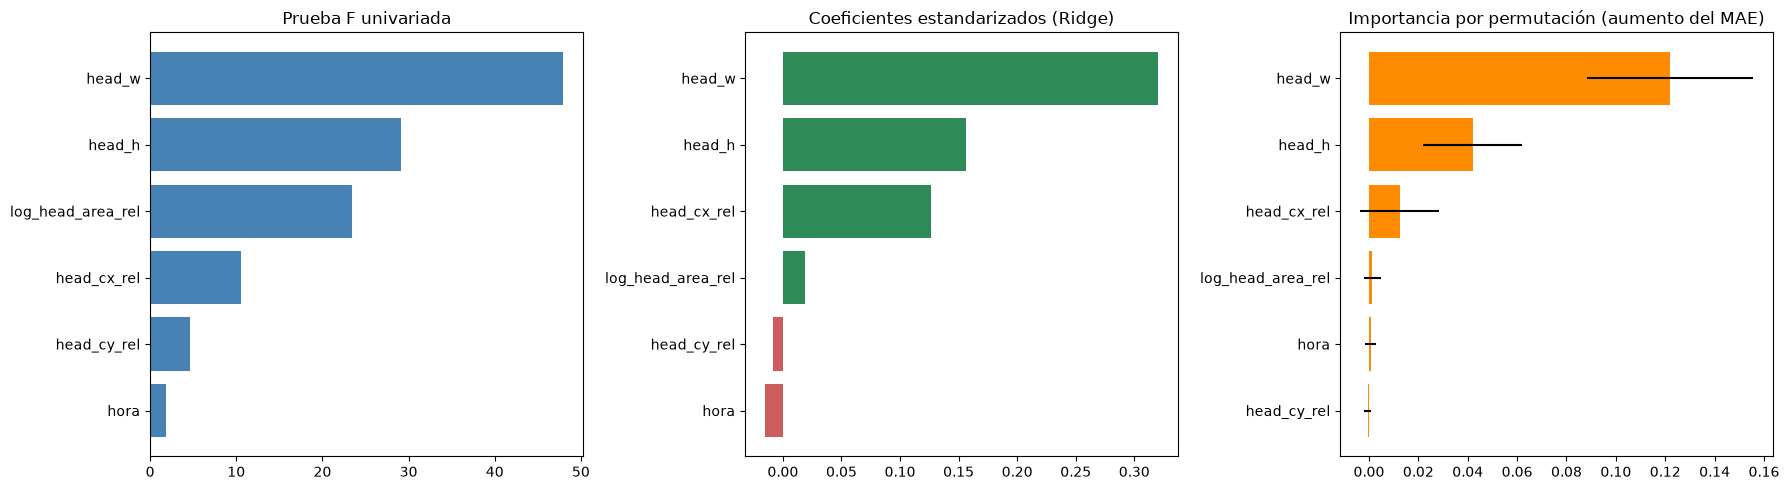

,F,p_valor
head_w,47.8669,0.0000
head_h,29.1719,0.0000
log_head_area_rel,23.4050,0.0000
head_cx_rel,10.5718,0.0022
head_cy_rel,4.6194,0.0369
hora,1.8036,0.1859


In [3]:
# 1. Filtro: estadístico F y valor p
F, p = f_regression(X_train, y_train)
filtro = pd.DataFrame({"F": F, "p_valor": p}, index=FEATURES).sort_values("F", ascending=False)

# 2. Coeficientes estandarizados (Ridge)
coefs = pd.Series(ridge.named_steps["ridge"].coef_, index=FEATURES).sort_values()

# 3. Importancia por permutación (sobre entrenamiento)
perm = permutation_importance(ridge, X_train, y_train, n_repeats=50, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
perm_std = pd.Series(perm.importances_std, index=FEATURES)[perm_s.index]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].barh(filtro.index[::-1], filtro["F"][::-1], color="steelblue")
axes[0].set_title("Prueba F univariada")
axes[1].barh(coefs.index, coefs.values, color=np.where(coefs.values >= 0, "seagreen", "indianred"))
axes[1].set_title("Coeficientes estandarizados (Ridge)")
axes[2].barh(perm_s.index, perm_s.values, xerr=perm_std.values, color="darkorange")
axes[2].set_title("Importancia por permutación (aumento del MAE)")
plt.tight_layout()
plt.show()

filtro.round(4)

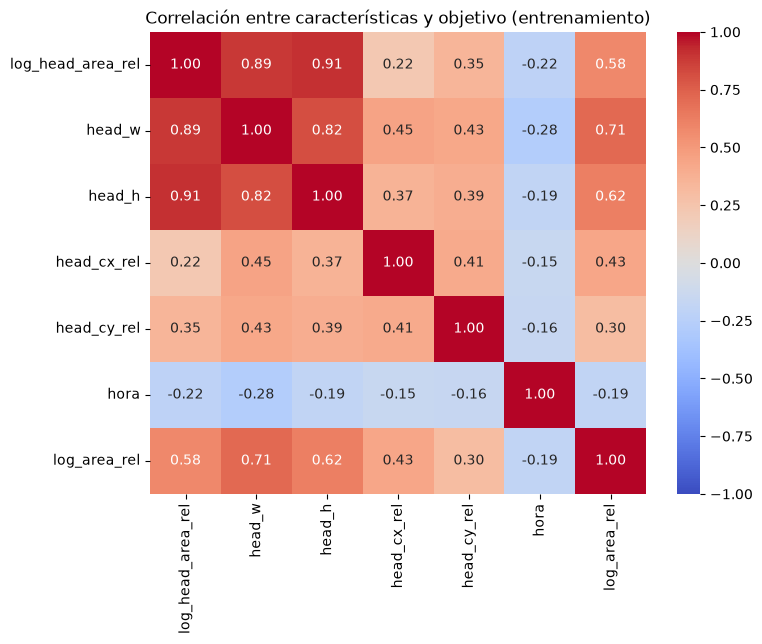

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(pd.concat([X_train, y_train], axis=1).corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre características y objetivo (entrenamiento)")
plt.show()

**Interpretación.** En la prueba F univariada solo `head_cx_rel` (posición horizontal de la cabeza) tiene un valor p menor a 0.05 (0.032). Al realizarse seis pruebas sobre 53 observaciones, ese resultado puede deberse al azar y no se considera evidencia sólida. Las variables de tamaño de la cabeza (`log_head_area_rel`, `head_h`, `head_w`) no resultan significativas, por lo que la hipótesis de proporcionalidad entre la cabeza y el objeto no se respalda con estos datos. Estas tres variables presentan alta correlación (aproximadamente 0.90 entre el área transformada y las dimensiones de la cabeza) y posible redundancia. En modelos posteriores se podría conservar solo una de ellas, decisión que debe evaluarse mediante validación. La importancia obtenida proviene de un modelo con bajo rendimiento, por lo que no permite concluir que una variable sea inútil; solo indica que no aportó a la predicción en esta evaluación.

## Sub/sobre ajuste

Se comparan las métricas de entrenamiento y validación cruzada agrupada por imagen (solo con el conjunto de entrenamiento) y se construye una curva de aprendizaje. Las métricas están en la escala del objetivo transformado (logarítmica).

In [5]:
cv = GroupKFold(n_splits=5)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

filas_cv = []
for nombre, m in construir_modelos().items():
    r = cross_validate(m, X_train, y_train, groups=g_train, cv=cv, scoring=scoring, return_train_score=True)
    filas_cv.append({"Modelo": nombre,
                     "MAE train": -r["train_mae"].mean(), "MAE val": -r["test_mae"].mean(), "MAE val (std)": r["test_mae"].std(),
                     "RMSE val": -r["test_rmse"].mean(),
                     "R2 train": r["train_r2"].mean(), "R2 val": r["test_r2"].mean(), "R2 val (std)": r["test_r2"].std()})
cv_res = pd.DataFrame(filas_cv).set_index("Modelo")
cv_res.round(3)

,MAE train,MAE val,MAE val (std),RMSE val,R2 train,R2 val,R2 val (std)
Modelo,,,,,,,
Ingenuo (media),0.601,0.602,0.186,0.770,0.000,-0.128,0.115
Regresión lineal,0.425,0.534,0.129,0.662,0.569,-0.414,1.200
Ridge (alpha=10),0.458,0.574,0.129,0.678,0.511,-0.343,1.105


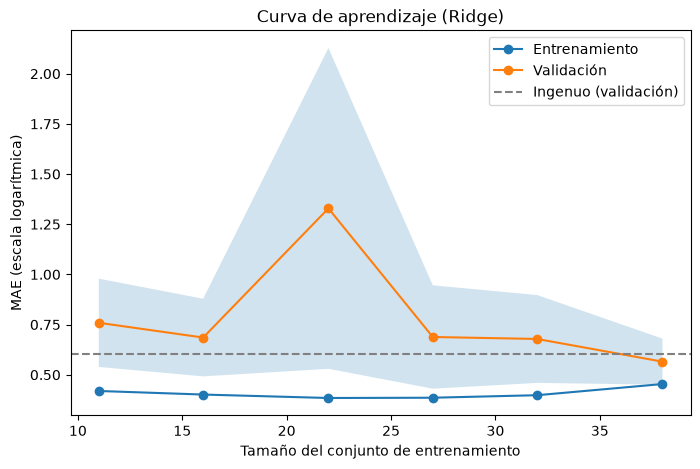

In [6]:
sizes, tr_sc, va_sc = learning_curve(
    make_pipeline(StandardScaler(), Ridge(alpha=10.0)), X_train, y_train, groups=g_train, cv=cv,
    train_sizes=np.linspace(0.3, 1.0, 6), scoring="neg_mean_absolute_error")

plt.figure(figsize=(8, 5))
plt.plot(sizes, -tr_sc.mean(axis=1), "o-", label="Entrenamiento")
plt.plot(sizes, -va_sc.mean(axis=1), "o-", label="Validación")
plt.fill_between(sizes, -va_sc.mean(axis=1) - va_sc.std(axis=1), -va_sc.mean(axis=1) + va_sc.std(axis=1), alpha=0.2)
plt.axhline(cv_res.loc["Ingenuo (media)", "MAE val"], color="gray", linestyle="--", label="Ingenuo (validación)")
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("MAE (escala logarítmica)")
plt.title("Curva de aprendizaje (Ridge)")
plt.legend()
plt.show()

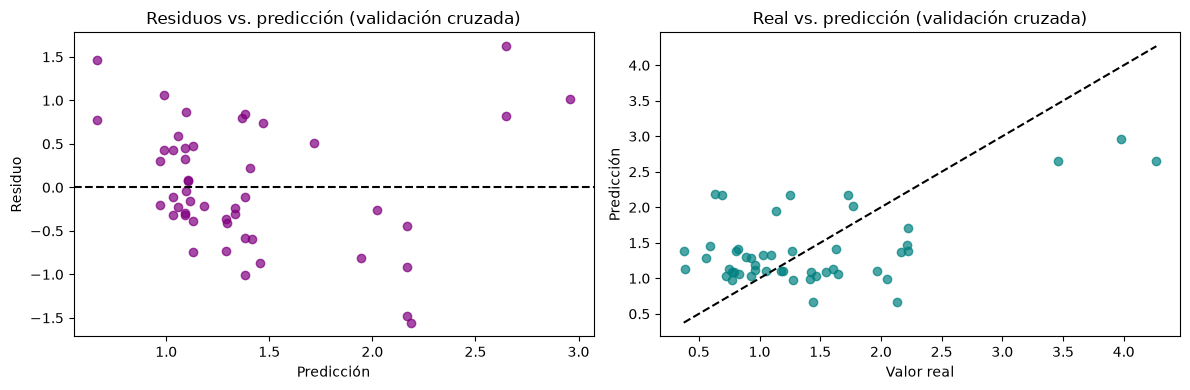

In [7]:
# Residuos de validación cruzada (cada observación predicha por un modelo que no la vio)
pred_cv = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=10.0)), X_train, y_train, groups=g_train, cv=cv)
res_cv = y_train - pred_cv

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(pred_cv, res_cv, color="purple", alpha=0.7)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Residuo")
axes[0].set_title("Residuos vs. predicción (validación cruzada)")
axes[1].scatter(y_train, pred_cv, color="teal", alpha=0.7)
lim = [min(y_train.min(), pred_cv.min()), max(y_train.max(), pred_cv.max())]
axes[1].plot(lim, lim, "k--")
axes[1].set_xlabel("Valor real")
axes[1].set_ylabel("Predicción")
axes[1].set_title("Real vs. predicción (validación cruzada)")
plt.tight_layout()
plt.show()

**Conclusión.** Los modelos lineales muestran signos de sobreajuste. La regresión lineal tiene un R² de 0.29 en entrenamiento y de -1.54 en validación cruzada, con una desviación estándar de 1.03 entre particiones, y su MAE de validación (0.586) es mayor que el de entrenamiento (0.353). Ridge reduce la brecha (R² de 0.18 contra -0.66, MAE de 0.381 contra 0.513), lo cual es consistente con el efecto de la regularización, pero su error de validación sigue por encima del modelo ingenuo (0.430). En la curva de aprendizaje el error de validación se mantiene por encima del de entrenamiento y de la referencia ingenua. Los residuos de validación cruzada sí muestran un patrón sistemático: las predicciones se concentran en un intervalo estrecho (aproximadamente de 0.21 a 1.44) frente al rango real del objetivo (de 0.33 a 2.92), de modo que el modelo tiende a sobreestimar los objetos pequeños y a subestimar los grandes (correlación de 0.88 entre el valor real y el residuo). La pendiente de la predicción respecto al valor real es prácticamente nula, lo que indica que el modelo casi no distingue entre objetos grandes y pequeños, un comportamiento propio de un modelo que se parece al promedio. La alta variabilidad entre particiones se debe al tamaño reducido del conjunto (53 observaciones de entrenamiento), por lo que las métricas son inestables.

## Métrica

El objetivo es continuo (proporción del área de la imagen), por lo que se trata de una regresión y no se emplean métricas de clasificación.

- **MAE (error absoluto medio):** métrica principal. Es robusta ante valores atípicos (hay objetos de tamaño extremo) y es fácil de comunicar.
- **MAE en escala original:** como el modelo se entrena sobre `log1p(area_rel * 1000)`, el MAE en escala logarítmica no equivale a un porcentaje de error sobre el área. Para interpretarlo se invierte la transformación (`expm1(predicción) / 1000`) y se reporta el error en puntos de `area_rel` y el **error relativo mediano**.
- **RMSE:** complementaria, penaliza más los errores grandes.
- **R²:** complementaria; indica cuánto mejora el modelo frente a predecir la media. Es negativo cuando el modelo es peor que esa referencia.

**Error tolerable.** Como criterio de trabajo se propone que el error relativo mediano sea menor a 30 % para que la estimación del tamaño sirva como referencia geométrica al validar detecciones. Este umbral es una suposición del equipo y debe ajustarse con el uso real previsto. Se propone porque, si la estimación se usara para filtrar detecciones del objeto comparando su tamaño con el esperado a partir de la cabeza, un error relativo menor a 30 % permitiría descartar cajas de tamaño claramente incompatible (por ejemplo, de varias veces el tamaño esperado) sin rechazar objetos válidos. Con errores mayores, el filtro eliminaría detecciones correctas. La tolerancia requiere validación operativa con datos reales.

## Desempeño

No existe un desempeño histórico para esta tarea (la verificación de vestimenta no se automatiza actualmente), por lo que el **desempeño mínimo** es el del modelo ingenuo que predice la media del entrenamiento.

**Regla de aceptación (única):** el baseline se considera aceptable si su MAE de validación cruzada es menor que el del modelo ingenuo y, además, su error relativo mediano en la escala original es menor al umbral de 30 % definido en la sección anterior. El R² y el RMSE se reportan de forma complementaria y no forman parte de la regla.

In [8]:
def a_escala_original(v):
    return np.expm1(v) / 1000

def evaluar_original(modelo, Xa, ya):
    pred = modelo.predict(Xa)
    real_o, pred_o = a_escala_original(ya), a_escala_original(pred)
    return {"MAE log": mean_absolute_error(ya, pred),
            "RMSE log": np.sqrt(mean_squared_error(ya, pred)),
            "R2": r2_score(ya, pred),
            "MAE area_rel": mean_absolute_error(real_o, pred_o),
            "Error relativo mediano": np.median(np.abs(real_o - pred_o) / real_o)}

# Predicciones de validación cruzada en escala original (entrenamiento)
filas = []
for nombre, m in construir_modelos().items():
    pred = cross_val_predict(m, X_train, y_train, groups=g_train, cv=cv)
    real_o, pred_o = a_escala_original(y_train), a_escala_original(pred)
    filas.append({"Modelo": nombre,
                  "MAE area_rel": mean_absolute_error(real_o, pred_o),
                  "Error relativo mediano": np.median(np.abs(real_o - pred_o) / real_o)})
val_orig = pd.DataFrame(filas).set_index("Modelo")
print("Validación cruzada (escala original)")
display(val_orig.round(4))

mae_ing = cv_res.loc["Ingenuo (media)", "MAE val"]
mae_rdg = cv_res.loc["Ridge (alpha=10)", "MAE val"]
err_rel = val_orig.loc["Ridge (alpha=10)", "Error relativo mediano"]
mejora = 100 * (mae_ing - mae_rdg) / mae_ing
cumple_ing = mae_rdg < mae_ing
cumple_tol = err_rel < 0.30

print(f"MAE validación (log) - Ingenuo: {mae_ing:.3f} | Ridge: {mae_rdg:.3f} | Mejora: {mejora:.1f}%")
print(f"Error relativo mediano de Ridge: {err_rel:.1%} (umbral 30%)")
print("Supera al ingenuo:", bool(cumple_ing), "| Cumple tolerancia:", bool(cumple_tol))
print("Baseline aceptable:", bool(cumple_ing and cumple_tol))

Validación cruzada (escala original)


,MAE area_rel,Error relativo mediano
Modelo,,
Ingenuo (media),0.0048,0.6488
Regresión lineal,0.0034,0.6237
Ridge (alpha=10),0.0043,0.6257


MAE validación (log) - Ingenuo: 0.602 | Ridge: 0.574 | Mejora: 4.6%
Error relativo mediano de Ridge: 62.6% (umbral 30%)
Supera al ingenuo: True | Cumple tolerancia: False
Baseline aceptable: False


In [9]:
# Evaluación final única sobre el conjunto de prueba reservado
filas_t = []
for nombre, m in modelos.items():
    r = evaluar_original(m, X_test, y_test)
    r["Modelo"] = nombre
    filas_t.append(r)
test_res = pd.DataFrame(filas_t).set_index("Modelo")
test_res.round(4)

,MAE log,RMSE log,R2,MAE area_rel,Error relativo mediano
Modelo,,,,,
Ingenuo (media),0.7611,0.9487,-0.0144,0.0057,0.9097
Regresión lineal,0.6743,0.8542,0.1775,0.0041,0.7364
Ridge (alpha=10),0.5970,0.8097,0.2611,0.0042,0.5795


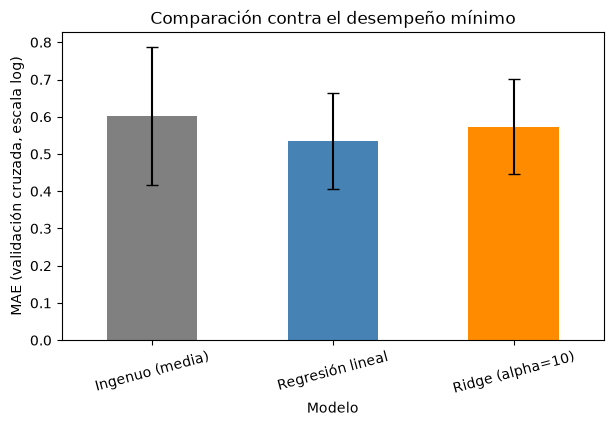

In [10]:
plt.figure(figsize=(7, 4))
cv_res["MAE val"].plot(kind="bar", color=["gray", "steelblue", "darkorange"], yerr=cv_res["MAE val (std)"], capsize=4)
plt.ylabel("MAE (validación cruzada, escala log)")
plt.title("Comparación contra el desempeño mínimo")
plt.xticks(rotation=15)
plt.show()

**Resultado.** Según la regla de aceptación definida, el baseline **no es aceptable**:
- En validación cruzada, Ridge no supera al modelo ingenuo (MAE de 0.513 contra 0.430 en escala logarítmica).
- Su error relativo mediano en la escala original es de 71 %, por encima del umbral de 30 %.

En el conjunto de prueba reservado (14 observaciones) Ridge queda ligeramente por debajo del ingenuo en MAE (0.370 contra 0.389) y con un R² cercano a cero (0.007), pero esa diferencia es pequeña y proviene de muy pocas observaciones, mientras que la validación cruzada indica lo contrario. El resultado de prueba no se utiliza para modificar el modelo ni la regla de aceptación.

Lo que se demuestra es que estos modelos, con estas variables y este protocolo de evaluación, no mejoraron la referencia. No se concluye que los datos carezcan de información: el conjunto es pequeño y la asociación objeto-cabeza se hizo por cercanía, lo que puede introducir errores.

## Conclusiones

- Se estableció un baseline con regresión lineal regularizada (Ridge) y un modelo ingenuo como desempeño mínimo, ya que no existe un desempeño histórico. El planteamiento es un experimento preliminar de relación geométrica entre la cabeza y el objeto, no una medida directa del cumplimiento del estándar.
- Para evitar fuga de información, solo se usaron como entradas variables de la cabeza y la hora, y el análisis se realizó con validación agrupada por imagen y un conjunto de prueba reservado.
- Con la regla de aceptación definida, el baseline no es aceptable: no supera al modelo ingenuo en validación cruzada y su error relativo mediano (71 %) excede el umbral de 30 %.
- Ninguna de las variables de tamaño de la cabeza resultó significativa. La hipótesis de proporcionalidad no se respalda con los datos actuales, aunque esto no permite descartarla.
- Hay sobreajuste en los modelos lineales y alta variabilidad entre particiones por el tamaño reducido del conjunto.
- Siguientes pasos: ampliar la captura de imágenes, validar manualmente la asociación objeto-cabeza, incluir ejemplos que sí cumplen el estándar para plantear un problema de clasificación y comparar modelos más complejos contra esta referencia.